# Perché il numero di input domina: varianza di $N_1$ vs complessità

Per costruzione
$$CQ_p = \alpha \sum_{p'} C_{p'p}\, Q_{p'} = \alpha\, N_1(p)\, \langle Q\rangle_{\mathrm{in}}(p),
\qquad \langle Q\rangle_{\mathrm{in}}(p) = \frac{1}{N_1(p)}\sum_{p'} C_{p'p} Q_{p'}$$
quindi
$$\mathrm{Var}(\log CQ) = \mathrm{Var}(\log N_1) + \mathrm{Var}(\log\langle Q\rangle_{\mathrm{in}}) + 2\,\mathrm{Cov}(\log N_1, \log\langle Q\rangle_{\mathrm{in}}).$$
Se il primo termine domina, l'ordinamento di CQ (e quindi di Q per a ≳ 1) è determinato dal numero di input.
$\langle Q\rangle_{\mathrm{in}}$ varia poco perché è una media su input che provengono da molti settori diversi.

Contenuto:
1. scomposizione della varianza di log CQ
2. distribuzioni di N_1, ⟨Q⟩_in, Q (normalizzate alla media)
3. distribuzioni di Q e Δ a HS6, HS4 e HS2 (HS2 = media dei prodotti del capitolo)
4. da quanti settori (capitoli HS2) provengono gli input di ogni prodotto

Metriche da `results/econometria/metriche/` (via `src/storage.py`) (notebook `data_generation/metriche_anni.ipynb`), C classica.
Figure in PDF in `plots/econometria/varianza_input/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.storage import load_metrics_long
import matplotlib.pyplot as plt
from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)

set_style()

## Configurazione

In [2]:
YEAR = 2002
RESOLUTIONS = [4, 6]
ALGOS = ["extended_fitness", "extended_eci"]
ALGO_LABEL = {"extended_fitness": "Extended Fitness", "extended_eci": "Extended ECI"}
ALGO_SHORT = {"extended_fitness": "fitness_est", "extended_eci": "eci_est"}     # per i nomi dei file
# le figure delle distribuzioni si fanno solo per questa combinazione (le altre danno lo stesso quadro,
# i numeri di tutte sono nelle tabelle stampate)
PLOT_RES, PLOT_ALGO = 4, "extended_fitness"

DATA = ROOT / "data" / "HS02_all_years"
SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "econometria" / "varianza_input" 

## Dati

In [3]:
def load_C(res):
    return pd.read_parquet(DATA / f"{res}_digits" / "alligned" / "binarized" / "C" / f"C_{res}_digits_HS02.parquet")

def load_products(res, year=YEAR):
    r = load_metrics_long(res, "product", years=[year])
    return r.pivot_table(index="product", columns=["metric", "variable"], values="value")

def decomposition_frame(res, algo):
    # N_1, <Q>_in, Q, Delta, CQ per ogni prodotto con almeno un input
    C = load_C(res)
    P = load_products(res)
    Q = P[(algo, "Q")].reindex(C.index)
    N1 = C.sum(axis=0)                                   # colonna p = input di p
    Qin = (C.T.values @ Q.values) / N1.replace(0, np.nan).values
    df = pd.DataFrame({"N1": N1, "Qin": Qin, "Q": Q,
                       "Delta": P[(algo, "Delta")].reindex(C.index),
                       "CQ": P[(algo, "CQ")].reindex(C.index)})
    return df[df["N1"] > 0]

frames = {(res, algo): decomposition_frame(res, algo) for res in RESOLUTIONS for algo in ALGOS}
# controllo: la CQ dell'algoritmo deve essere proporzionale a N_1 <Q>_in
for k, df in frames.items():
    r = np.corrcoef(np.log(df["CQ"]), np.log(df["N1"] * df["Qin"]))[0, 1]
    print(k, f"corr(log CQ, log N1<Q>_in) = {r:.4f}")

(4, 'extended_fitness') corr(log CQ, log N1<Q>_in) = 1.0000
(4, 'extended_eci') corr(log CQ, log N1<Q>_in) = 1.0000
(6, 'extended_fitness') corr(log CQ, log N1<Q>_in) = 1.0000
(6, 'extended_eci') corr(log CQ, log N1<Q>_in) = 1.0000


## 1. Scomposizione della varianza di log CQ

In [4]:
rows = []
for (res, algo), df in frames.items():
    lN, lQ = np.log(df["N1"]), np.log(df["Qin"])
    rows.append({"res": res, "algo": algo,
                 "Var(log N1)": np.var(lN), "Var(log <Q>_in)": np.var(lQ),
                 "2 Cov": 2 * np.cov(lN, lQ, bias=True)[0, 1], "Var(log CQ)": np.var(lN + lQ)})
dec = pd.DataFrame(rows)
dec["quota N1"] = dec["Var(log N1)"] / dec["Var(log CQ)"]
dec["quota <Q>_in"] = dec["Var(log <Q>_in)"] / dec["Var(log CQ)"]
dec.round(3)

,res,algo,Var(log N1),Var(log <Q>_in),2 Cov,Var(log CQ),quota N1,quota <Q>_in
0,4,extended_fitness,1.652,0.266,0.440,2.359,0.701,0.113
1,4,extended_eci,1.652,0.093,0.148,1.893,0.873,0.049
2,6,extended_fitness,2.255,0.240,0.436,2.931,0.769,0.082
3,6,extended_eci,2.255,0.107,0.260,2.622,0.860,0.041


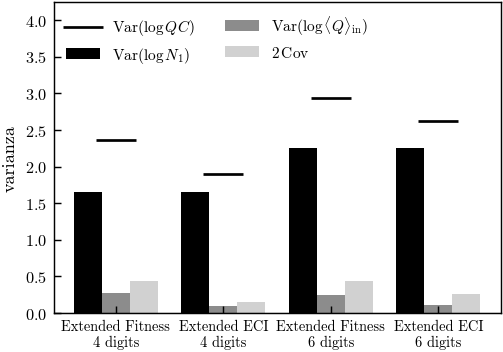

In [5]:
def plot_decomposition(dec):
    fig, ax = plt.subplots(figsize=figsize(*SINGLE))
    x = np.arange(len(dec))
    w = 0.26
    parts = [("Var(log N1)", PALETTE["N1"], r"$\mathrm{Var}(\log N_1)$"),
             ("Var(log <Q>_in)", PALETTE["Qin"], r"$\mathrm{Var}(\log \langle Q\rangle_{\mathrm{in}})$"),
             ("2 Cov", "0.82", r"$2\,\mathrm{Cov}$")]
    for j, (col, c, lab) in enumerate(parts):
        ax.bar(x + (j - 1) * w, dec[col], width=w, color=c, label=lab)
    ax.scatter(x, dec["Var(log CQ)"], marker="_", s=500, color="k", lw=1.5, zorder=3,
               label=r"$\mathrm{Var}(\log QC)$")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{ALGO_LABEL[a]}\n{r} digits" for r, a in zip(dec["res"], dec["algo"])], fontsize=8)
    ax.set_ylabel("varianza")
    ax.set_ylim(0, 1.45 * dec["Var(log CQ)"].max())
    ax.legend(loc="upper left", ncol=2)
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / "scomposizione_varianza")
    plt.show()

plot_decomposition(dec)

## 2. Distribuzioni di $N_1$, $\langle Q\rangle_{\mathrm{in}}$ e $Q$

Densità di probabilità di $X/\langle X\rangle$, stimata con kernel gaussiano su $\log_{10}$ e mostrata su asse x logaritmico
(la densità è per unità di $\log_{10}$): curva più stretta e alta = distribuzione più concentrata.
Figura solo per `PLOT_ALGO` a `PLOT_RES` digits; per le altre combinazioni si stampa il rapporto std/media.

extended_fitness, 4 digits — std/media: {'N1': 1.065, 'Qin': 0.426, 'Q': 0.839}
extended_eci, 4 digits — std/media: {'N1': 1.065, 'Qin': 0.32, 'Q': 0.573}
extended_fitness, 6 digits — std/media: {'N1': 1.176, 'Qin': 0.396, 'Q': 0.905}
extended_eci, 6 digits — std/media: {'N1': 1.176, 'Qin': 0.355, 'Q': 0.629}


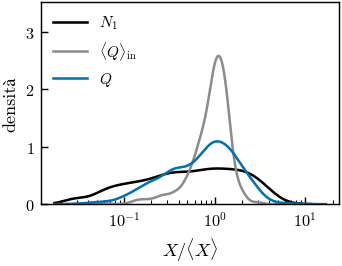

In [6]:
from scipy.stats import gaussian_kde

def density(ax, x, log, **kw):
    # densita' stimata con kernel gaussiano (larghezza di banda: regola di Scott);
    # con log=True la stima e' su log10(x) e la curva va letta su asse x logaritmico
    x = np.asarray(x, dtype=float)
    x = x[x > 0] if log else x
    z = np.log10(x) if log else x
    grid = np.linspace(z.min() - 0.1 * np.ptp(z), z.max() + 0.1 * np.ptp(z), 400)
    ax.plot(10 ** grid if log else grid, gaussian_kde(z)(grid), **kw)

def plot_distributions(res, algo, variables=("N1", "Qin", "Q")):
    df = frames[(res, algo)]
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    for v in variables:
        density(ax, df[v] / df[v].mean(), log=True, color=PALETTE[v], lw=1.4, label=SYMBOLS[v])
    ax.set_xscale("log")
    ax.set_xlabel(r"$X / \langle X \rangle$")
    ax.set_ylabel("densità")
    ax.set_ylim(0, 1.3 * ax.get_ylim()[1])          # spazio per la legenda sopra le curve
    ax.legend(loc="upper left")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"densita_N1_Qin_Q_{ALGO_SHORT[algo]}_hs{res}")
    plt.show()

for (res, algo), df in frames.items():
    print(f"{algo}, {res} digits — std/media:", {v: round(df[v].std() / df[v].mean(), 3) for v in ("N1", "Qin", "Q")})
plot_distributions(PLOT_RES, PLOT_ALGO)

## 3. Distribuzioni della complessità a HS6, HS4, HS2

HS6 e HS4 sono le metriche calcolate nativamente a quella risoluzione; HS2 è la media dei prodotti HS4 dello stesso capitolo
(con `HS2_FROM = 6` si aggrega invece da HS6). Ogni variabile è normalizzata alla sua media.

Densità stimate con kernel gaussiano (KDE): con numeri di prodotti così diversi fra i livelli (5079, 1205, 92)
un istogramma sarebbe poco confrontabile. Per le variabili che coprono più ordini di grandezza la stima è fatta
su $\log_{10}$ e l'asse x è logaritmico: in quel caso la densità è per unità di $\log_{10}$ (da scrivere in didascalia).
Figure: $Q$ di `PLOT_ALGO` e $\Delta$ di entrambe le metriche estese (usate nella tesi, fig. `distribuzioni-delta`);
per le altre combinazioni si riportano std/media e std(log) nella tabella.
Per le variabili molto concentrate (Δ dell'ECI esteso) l'asse x mostra il 99% centrale dei dati.

extended_fitness Q


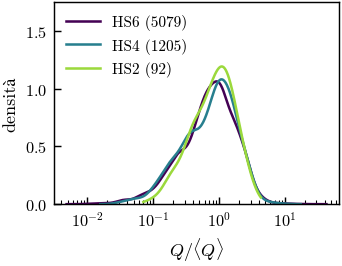

extended_fitness Delta


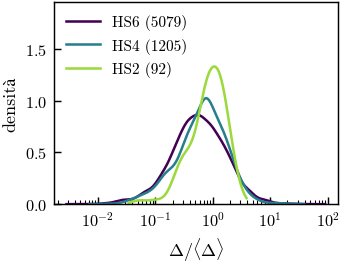

extended_eci Delta


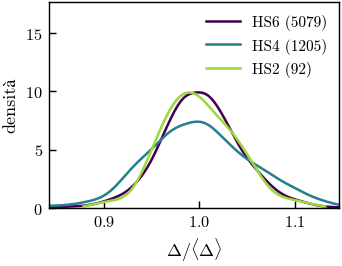

,algo,variabile,livello,n,std/media,std(log)
0,extended_fitness,Q,HS6,5079,0.963,0.966
1,extended_fitness,Q,HS4,1205,0.850,0.936
2,extended_fitness,Q,HS2,92,0.652,0.739
3,extended_fitness,Delta,HS6,5079,1.546,1.092
4,extended_fitness,Delta,HS4,1205,1.214,0.996
5,extended_fitness,Delta,HS2,92,0.582,0.725
6,extended_eci,Q,HS6,5079,0.634,0.501
7,extended_eci,Q,HS4,1205,0.580,0.487
8,extended_eci,Q,HS2,92,0.506,0.431
9,extended_eci,Delta,HS6,5079,0.054,0.041


In [7]:
HS2_FROM = 4
LEVEL_COLOR = {"HS6": SEQ_CMAP(0.0), "HS4": SEQ_CMAP(0.5), "HS2": SEQ_CMAP(1.0)}
VAR_LABEL = {"Q": r"$Q / \langle Q \rangle$", "Delta": r"$\Delta / \langle \Delta \rangle$"}

def levels(algo, var):
    q6 = load_products(6)[(algo, var)]
    q4 = load_products(4)[(algo, var)]
    base = q4 if HS2_FROM == 4 else q6
    q2 = base.groupby(base.index.str[:2]).mean()
    return {"HS6": q6, "HS4": q4, "HS2": q2}

cv_rows = []
for algo in ALGOS:
    for var in ["Q", "Delta"]:
        lv = levels(algo, var)
        for name, s_ in lv.items():
            cv_rows.append({"algo": algo, "variabile": var, "livello": name, "n": len(s_),
                            "std/media": s_.std() / s_.mean(), "std(log)": np.log(s_[s_ > 0]).std()})

def plot_levels(algo, var):
    lv = levels(algo, var)
    # scala log solo se la variabile copre piu' di un ordine di grandezza
    log = max(s_.max() / s_[s_ > 0].min() for s_ in lv.values()) > 10
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    for name, s_ in lv.items():
        density(ax, s_ / s_.mean(), log, color=LEVEL_COLOR[name], lw=1.4, label=f"{name} ({len(s_)})")
    if log:
        ax.set_xscale("log")
    else:
        # vista sul 99% centrale dei dati: pochi prodotti isolati allungherebbero l'asse
        allv = pd.concat([s_ / s_.mean() for s_ in lv.values()])
        lo, hi = allv.quantile([0.005, 0.995])
        ax.set_xlim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax.set_ylim(0, (1.4 if log else 1.7) * ax.get_ylim()[1])   # spazio per la legenda sopra le curve
    ax.set_xlabel(VAR_LABEL[var])
    ax.set_ylabel("densità")
    ax.legend(loc="upper left" if log else "upper right")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"densita_{var}_HS_{ALGO_SHORT[algo]}")
    print(algo, var)
    plt.show()

for algo, var in ((PLOT_ALGO, "Q"), ("extended_fitness", "Delta"), ("extended_eci", "Delta")):
    plot_levels(algo, var)

pd.DataFrame(cv_rows).round(3)

## 4. Da quanti settori provengono gli input

Per ogni prodotto: numero di capitoli HS2 distinti fra i suoi input e quota di input dal proprio capitolo.
Figura: densità del numero di capitoli (istogramma normalizzato, un bin per valore); la quota dal proprio capitolo è riportata solo nel testo.

4 digits: capitoli distinti fra gli input — mediana 7; quota di input dal proprio capitolo — mediana 0.14, media 0.23
6 digits: capitoli distinti fra gli input — mediana 7; quota di input dal proprio capitolo — mediana 0.17, media 0.27


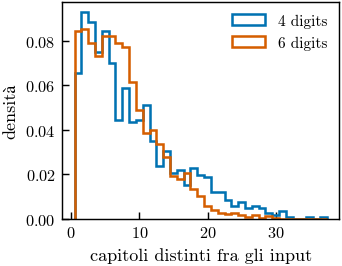

In [8]:
def input_sectors(res):
    C = load_C(res)
    chap = C.index.str[:2].to_numpy()
    rows = []
    for j, p in enumerate(C.columns):
        inp = np.flatnonzero(C.values[:, j])
        if len(inp) == 0:
            continue
        rows.append({"product": p, "N1": len(inp), "n_capitoli": len(set(chap[inp])),
                     "quota_stesso_capitolo": np.mean(chap[inp] == p[:2])})
    return pd.DataFrame(rows)

sectors = {res: input_sectors(res) for res in RESOLUTIONS}
for res, s in sectors.items():
    print(f"{res} digits: capitoli distinti fra gli input — mediana {s.n_capitoli.median():.0f}; "
          f"quota di input dal proprio capitolo — mediana {s.quota_stesso_capitolo.median():.2f}, "
          f"media {s.quota_stesso_capitolo.mean():.2f}")

max_cap = max(s.n_capitoli.max() for s in sectors.values())
fig, ax = plt.subplots(figsize=figsize(*HALF))
for res, s in sectors.items():
    ax.hist(s["n_capitoli"], bins=np.arange(0.5, max_cap + 1.5), density=True, histtype="step",
            color=PALETTE[res], lw=1.4, label=f"{res} digits")
ax.set_xlabel("capitoli distinti fra gli input")
ax.set_ylabel("densità")
ax.legend(loc="upper right")
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / "densita_n_capitoli")
plt.show()